# Example: KMT-2025-BLG-1314 — planet or stellar binary, ten solutions

This is one of a series of example notebooks that run lenscape's map pipeline, with its default settings, on
published events, and compare the maps with the published ones.

**The event.** KMT-2025-BLG-1314 (Ren, Zang, Zhu et al. 2026, *KMT-2025-BLG-1314 and KMT-2025-BLG-1392: two
microlensing planetary/brown-dwarf candidates analyzed with differentiable code*, arXiv:2603.01735) is a
high-magnification event (*u*₀ ≈ 0.003, *t*ₑ ≈ 70 d, faint source) that peaked on HJD′ ≈ 10841.21. The peak shows an
asymmetric, double-bump feature, covered by KMTNet's auto-follow-up at KMTA and KMTS and by LCOGT at SSO and SAAO.
The paper finds **ten solutions within Δχ² = 14**: four planetary ones (log *q* ≈ −3.2 to −3.7, close and wide, with
and without a measured finite source) and six stellar-binary ones (log *q* from −1 to +1.1, log *s* ≈ ±1.0 to 1.4).
This is the "planet/binary" degeneracy of a source passing near a central caustic cusp.

**Their map.** A grid in caustic width log *w*, log *q* and α (40 × 60 × 10 points over −3.5 ≤ log *w* ≤ −2.0,
−5 ≤ log *q* ≤ 2), minimised with CMA-ES at each point, then projected onto the (log *s*, log *q*) plane; points with
Δχ² > 49 are left blank. It is not a regular grid in (log *s*, log *q*). The light curves are computed with
VBMicrolensing and the posteriors with the differentiable code microlux.

**What is different here.** The LCOGT data are not public; we use the KMTNet data, including the auto-follow-up
points. Our 1× map is a regular lattice over the region of the paper's (log *s*, log *q*) panel. lenscape uses a
uniform source; the paper used limb darkening.

## 0. Setup

In [1]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
import lenscape
from lenscape import figures

RECOMPUTE = False              # True: compute the best fit and all maps again; False: compute only what data/ lacks
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")


def run_or_load(name, compute):
    # data/kb251314_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/kb251314_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/kb251314_photometry.csv` holds the public KMTNet pySIS photometry (field BLG11, *I* band, HJD′ 10760–10920) of
KMTC11, KMTS11 and KMTA11, as it comes from the KMTNet event archive (no error rescaling, no outlier removal). The
archive includes the auto-follow-up points at the peak.

In [2]:
rows = np.genfromtxt("data/kb251314_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
SETS = ["KMTC11", "KMTS11", "KMTA11"]
# pySIS Delta_flux falls as the star brightens; flip the sign so that brighter is up. The fit does not care: the
# source and blend fluxes change sign, chi2 is identical.
raw = lenscape.Data.from_sets({n: (rows["t"][rows["set"] == n], -rows["flux"][rows["set"] == n],
                                   rows["flux_err"][rows["set"] == n]) for n in SETS})
raw

Data(1069 points, t 10760.48 .. 10919.65, sets {'KMTC11': 500, 'KMTS11': 298, 'KMTA11': 271})

## 2. Error bars and the best fit

The pySIS error bars are not normalised. As in the papers, we rescale them per data set so that the best fit has
χ²/N = 1 (Yee et al. 2012; here with a factor *k* only, σ′ = *k* σ), and we remove points more than 5σ off the best
fit. The best fit starts from the published solutions (Table below). The papers and lenscape measure the trajectory
angle α and the sign of *u*₀ in different conventions, so each published solution is tried in the four equivalent
forms (α, 2π − α, π − α, α + π) with both signs of *u*₀, and the best start is refined with `lenscape.fit_full`.
Then every published solution is refitted on the final data, which shows how well these data separate them.

The result is stored in `data/kb251314_bestfit.json`; the fits take a few minutes and run only if that file is missing.

In [3]:
SOLUTIONS = {        # the paper's Table 2 (t0, u0 relative to its reference point; rho None: upper limit only)
    "close planet finite": (10841.212, 0.00315, 74.004, 0.7534, 0.0002239, 1.6428, 0.001824),
    "close planet point": (10841.214, 0.00310, 71.424, 0.5559, 0.0005781, 1.6318, None),
    "wide planet finite": (10841.213, 0.00311, 74.481, 1.3366, 0.0002393, 1.6341, 0.001811),
    "wide planet point": (10841.214, 0.00310, 70.493, 1.9011, 0.0006653, 1.6364, None),
    "close binary BC": (10841.210, 0.003338, 66.779, 0.091, 14.06, 2.467, None),
    "wide binary DA": (10841.209, 0.003174, 70.599, 13.614, 0.1054, 5.6092, None),
}          # published: (t0, u0, tE, s, q, alpha [rad], rho); rho None = not measured


def as_vector(sol):
    t0, u0, tE, s, q, al, rho = sol
    return np.array([t0, u0, tE, np.log10(s), np.log10(q), al, np.log10(rho if rho else 1e-3)])


def variants(p):
    out = []
    for sg in (1, -1):
        for a in (p[5], 2 * np.pi - p[5], np.pi - p[5], p[5] + np.pi):
            v = p.copy(); v[1] = sg * abs(p[1]); v[5] = a % (2 * np.pi); out.append(v)
    return out


be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
path = "data/kb251314_bestfit.json"
if RECOMPUTE or not os.path.exists(path):
    log("best fit: starts from the published solutions")
    d = raw
    starts = sorted(((lenscape.model.chi2(be, v, d), name, v) for name, sol in SOLUTIONS.items()
                     for v in variants(as_vector(sol))), key=lambda z: z[0])
    c, p = min((lenscape.fit_full(d, v, rounds=2) for _, _, v in starts[:4]), key=lambda z: z[0])
    r = lenscape.model.residuals(be, p, d)
    keep = np.ones(len(d), bool)
    for k in range(d.nsets):
        m = d.idx == k
        keep[m] = np.abs(r[m]) < 5 * np.sqrt(np.mean(r[m] ** 2))
    d = raw.select(keep)
    kfac = {n: 1.0 for n in d.names}
    for _ in range(3):
        c, p = lenscape.fit_full(d.scale_errors(kfac), p, rounds=2)
        f = lenscape.fit.error_factors(d.scale_errors(kfac), p)
        kfac = {n: kfac[n] * f[n] for n in d.names}
    data = d.scale_errors(kfac)
    c, p = lenscape.fit_full(data, p)
    per_sol = {}
    for name, sol in SOLUTIONS.items():                 # every published solution on the final data
        v = min(variants(as_vector(sol)), key=lambda v: lenscape.model.chi2(be, v, data))
        cs, ps = lenscape.fit_full(data, v, rounds=2)
        per_sol[name] = dict(chi2=cs, p=list(ps))
        log(f"  {name}: chi2 {cs:.1f}")
    name_best = min(per_sol, key=lambda n: per_sol[n]["chi2"])
    if per_sol[name_best]["chi2"] < c:                  # a published solution refits lower: it is the best fit
        c, p = per_sol[name_best]["chi2"], np.array(per_sol[name_best]["p"])
    json.dump(dict(p=list(p), chi2=c, k=kfac, keep=keep.tolist(), N=len(data), solutions=per_sol), open(path, "w"))
bf = json.load(open(path))
data = raw.select(np.array(bf["keep"])).scale_errors(bf["k"])
best = np.array(bf["p"])
chi2_best = lenscape.model.chi2(be, best, data)
print(f"{len(raw) - len(data)} points removed, {len(data)} left; error factors k:",
      ", ".join(f"{n} {v:.2f}" for n, v in bf["k"].items()))
print(f"best fit: chi2 = {chi2_best:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4]:.3e}, "
      f"tE = {best[2]:.2f} d, rho = {10 ** best[6]:.2e}")
print("\npublished solutions refitted on these data:")
for name, s in bf["solutions"].items():
    p = np.array(s["p"])
    if s["chi2"] > 10 * len(data):                      # diverged: the paper's reference point differs from ours
        print(f"  {name:22s} refit from the published values failed (chi2 {s['chi2']:.3g})")
        continue
    print(f"  {name:22s} Delta chi2 = {s['chi2'] - bf['chi2']:7.1f}   log s = {p[3]:+.3f}  log q = {p[4]:+.3f}  "
          f"tE = {p[2]:6.1f} d  log rho = {p[6]:+.2f}")

9 points removed, 1060 left; error factors k: KMTC11 1.48, KMTS11 2.24, KMTA11 2.41
best fit: chi2 = 1060.0 for 1060 points;  s = 0.0673, q = 5.717e+00, tE = 65.10 d, rho = 8.16e-04

published solutions refitted on these data:
  close planet finite    Delta chi2 =     1.2   log s = -0.120  log q = -3.613  tE =   68.5 d  log rho = -2.73
  close planet point     Delta chi2 =     1.6   log s = -0.250  log q = -3.274  tE =   71.9 d  log rho = -3.07
  wide planet finite     Delta chi2 =     1.2   log s = +0.116  log q = -3.625  tE =   69.3 d  log rho = -2.73
  wide planet point      Delta chi2 =    10.3   log s = +0.695  log q = -2.772  tE =  488.0 d  log rho = -3.75
  close binary BC        Delta chi2 =     0.1   log s = -1.119  log q = +0.948  tE =   69.9 d  log rho = -3.14
  wide binary DA         Delta chi2 =    93.3   log s = +0.343  log q = -0.010  tE =    6.7 d  log rho = -1.43


The paper's ten solutions span Δχ² = 0.2 to 14.2 with its data (KMTNet and LCOGT). We refit the four planetary
solutions and the best close and wide binary solutions; the others are listed in the paper's Table 2.

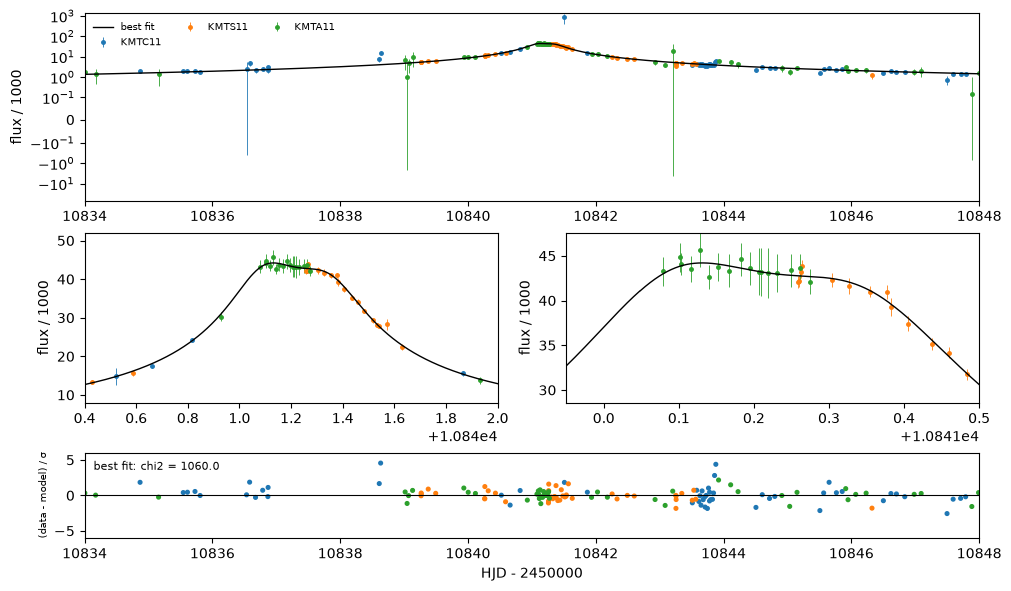

In [4]:
WINDOW, ZOOMS = (10834.0, 10848.0), ((10840.4, 10842.0), (10840.95, 10841.5))


def plot_flux(sols, window=WINDOW, zooms=ZOOMS, d=None):
    # data of all sets on the flux scale of the first set (aligned with the best fit), the first set's model of each
    # solution, two zooms and one panel of normalised residuals per solution (each with its own fluxes); the top
    # panel has a symmetric-log flux axis
    d = data if d is None else d
    styles = ["-", ":", "--", "-.", (0, (5, 1)), (0, (1, 3))]
    fs0, fb0 = lenscape.model.fluxes(lenscape.model.magnification(be, best, d), d)
    fig = plt.figure(figsize=(10, 4.8 + 1.0 * len(sols)), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.2, 2.0] + [1] * len(sols))
    top = fig.add_subplot(gs[0, :]); zax = [fig.add_subplot(gs[1, k]) for k in range(2)]
    for ax, (a, b) in zip([top] + zax, [window] + list(zooms)):
        lo, hi = [], []
        tt = np.linspace(a, b, 4000)
        for (name, p), ls in zip(sols.items(), styles):
            fs, fb = lenscape.model.fluxes(lenscape.model.magnification(be, p, d), d)
            mod = (fs[0] * be.lc(lenscape.model.clamp(p)[0], tt) + fb[0]) / 1e3
            ax.plot(tt, mod, linestyle=ls, color="k", lw=1, label=name if ax is top else None, zorder=3)
            lo.append(mod.min()); hi.append(mod.max())
        for k, name in enumerate(d.names):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            f = (d.f[m] - fb0[k]) / fs0[k] * fs0[0] + fb0[0]
            ax.errorbar(d.t[m], f / 1e3, d.e[m] * abs(fs0[0] / fs0[k]) / 1e3, fmt="o", ms=2.5, lw=0.6,
                        color=f"C{k}", label=name if ax is top else None, zorder=2)
        span = max(hi) - min(lo)
        ax.set_xlim(a, b); ax.set_ylabel("flux / 1000")
        if ax is not top:
            ax.set_ylim(min(lo) - 0.15 * span, max(hi) + 0.25 * span)
    top.set_yscale("symlog", linthresh=max(abs(fb0[0] + fs0[0]) / 1e3, 0.1))
    top.legend(fontsize=7, frameon=False, ncol=3, loc="upper left")
    for k, (name, p) in enumerate(sols.items()):
        ax = fig.add_subplot(gs[2 + k, :], sharex=top)
        r = lenscape.model.residuals(be, p, d)
        m = (d.t > window[0]) & (d.t < window[1])
        ax.scatter(d.t[m], r[m], s=7, c=[f"C{i}" for i in d.idx[m]]); ax.axhline(0, color="k", lw=0.8)
        ax.set_ylim(-6, 6); ax.set_ylabel("(data - model) / σ", fontsize=7)
        ax.text(0.01, 0.8, f"{name}: chi2 = {np.sum(r ** 2):.1f}", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel(f"HJD - {2450000}")
    return fig

plot_flux({"best fit": best});

For later comparison, here is the **single-lens floor**: the χ² of the best point-lens model (with a finite source),
measured against the binary best fit. Points of a map with Δχ² near this value are no better than having no planet
or companion at all.

In [5]:
def chi2_1l1s(x):
    A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], data.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, data)
    return float((((data.f - fs[data.idx] * A - fb[data.idx]) / data.e) ** 2).sum())

chi2_single = min(minimize(chi2_1l1s, [best[0], u0, best[2], lr], method="Nelder-Mead",
                           options=dict(maxfev=4000, adaptive=True)).fun
                  for u0 in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3) for lr in (-3.5, -2.5, -1.5))
floor = chi2_single - chi2_best
print(f"single-lens floor: Delta chi2 = {floor:.1f}")

single-lens floor: Delta chi2 = 17.2


On the public data the single-lens floor is only about 17: without the LCOGT points and with error factors
*k* = 1.5 to 2.4, the feature at the peak is barely significant. Every map below is therefore confined to Δχ² ≲ 20.

## 3. The paper's map

`data/kb251314_paper_grid.csv` holds the (log *s*, log *q*) panel of the paper's Fig. 3, read from the raster figure:
the figure plots one square marker per grid point, and we sample the panel on a
regular raster (0.02 dex in log *s*, 0.04 in log *q*) and keep the points that fall on a marker. The bands are
Δχ² < 4, 9, 16, 25, 36, 49; points above 49 are blank.

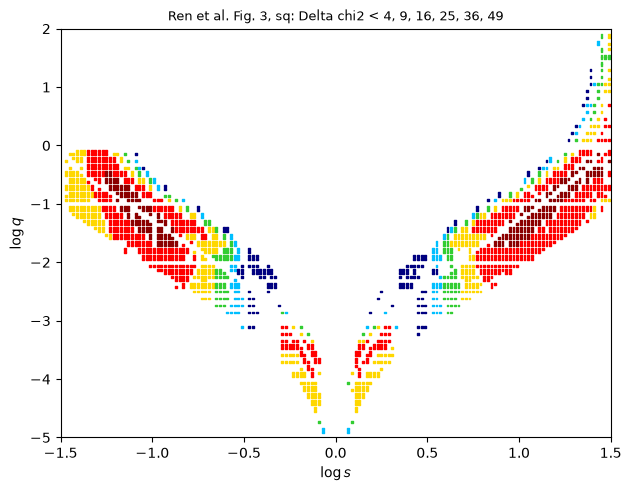

In [6]:
paper = np.genfromtxt("data/kb251314_paper_grid.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                      skip_header=2)
EDGES = np.array([4, 9, 16, 25, 36, 49])                         # the paper's band edges in Delta chi2
band_cmap = ListedColormap(["#8b0000", "red", "gold", "limegreen", "deepskyblue", "navy"] + ["white"])        # the paper's band colours, white above the last band
PANELS = {"sq": ((-1.5, 1.5), (-5.0, 2.0))}                                 # paper panel: (log s range, log q range)
fig, axs = plt.subplots(1, len(PANELS), figsize=(6.2 * len(PANELS), 4.8), constrained_layout=True, squeeze=False)
for ax, (panel, (sr, qr)) in zip(axs[0], PANELS.items()):
    sel = paper["panel"] == panel
    ax.scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap, vmin=-0.5,
               vmax=len(EDGES) + 0.5, marker="s", s=2)
    ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
    ax.set_title(f"Ren et al. Fig. 3, {panel}: Delta chi2 < " + ", ".join(f"{e:g}" for e in EDGES), fontsize=9)

## 4. Our 1× map

`lenscape.lattice` with all defaults on a regular lattice over the region of the paper's (log *s*, log *q*) panel:
61 points in −1.5 ≤ log *s* ≤ 1.5 (step 0.05) and 71 in −5 ≤ log *q* ≤ 2 (step 0.1). Stored in `data/`.

**The upper part of this lattice is redundant.** A binary lens with mass ratio *q* is the same lens as one with
1/*q*: the two masses swap places. lenscape works in the centre-of-mass frame with *s* and *t*ₑ in units of the total
mass, so *s*, *t*₀, *t*ₑ and ρ stay the same. Only the trajectory is mirrored: *u*₀ → −*u*₀ and α → π − α.
Every model at (log *s*, log *q*) therefore has a twin at (log *s*, −log *q*) with the same χ², and the profile χ²
of the map is exactly symmetric about log *q* = 0. (We checked: the mirrored parameter vectors give the same χ² to
0.02.)

Both the paper's grid (−5 ≤ log *q* ≤ 2) and our 1× lattice nevertheless computed the mirror region
0 < log *q* ≤ 2 a second time, 28 % of our points. **Maps should cover log *q* ≤ 0 only**, and any later densify or
zoom of this event would do so. Here we make use of the duplicate work: each point is a local fit, and the two
fits of a mirror pair do not always find the same minimum. So we **fold** the map, keeping the better fit of each
pair (with its parameters mirrored) at both points. Folding needs no new fits.

In [7]:
LS1, LQ1 = np.linspace(-1.5, 1.5, 61), np.linspace(-5.0, 2.0, 71)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, LS1, LQ1, best=best, log=log))
print(f"{map1['chi2'].shape[0]} x {map1['chi2'].shape[1]} points, wall time {map1['wall'] / 60:.0f} min")


def fold(m):
    # q <-> 1/q: the same lenses, mirrored trajectory (u0 -> -u0, alpha -> pi - alpha); keep the better fit of each pair
    lq, c0, p0 = m["logq"], m["chi2"], m["pars"]
    c, p = c0.copy(), p0.copy()
    for j in range(len(lq)):
        k = int(np.argmin(np.abs(lq + lq[j])))
        if abs(lq[k] + lq[j]) > 1e-6:
            continue                                   # no mirror point on the lattice (log q < -2)
        better = c0[:, k] < c[:, j]
        mp = p0[better, k].copy()
        mp[:, 1] *= -1
        mp[:, 3] = (np.pi - mp[:, 3]) % (2 * np.pi)
        c[better, j], p[better, j] = c0[better, k], mp
    return dict(m, chi2=c, pars=p, folded=True)


map1f = fold(map1)
gain = (map1["chi2"] - map1f["chi2"])[map1f["chi2"] - np.nanmin(map1f["chi2"]) < 49]
print(f"folding: {(gain > 0.1).sum()} of {gain.size} points with Delta chi2 < 49 improved; by > 2 at {(gain > 2).sum()}, "
      f"by > 5 at {(gain > 5).sum()}, at most by {gain.max():.1f}")
OURS = [("1x folded", map1f, "sq")]

61 x 71 points, wall time 395 min
folding: 575 of 3455 points with Delta chi2 < 49 improved; by > 2 at 307, by > 5 at 197, at most by 2188.7


### Our map next to the paper's

Each of our maps in the paper's bands (same band edges, no rescaling of Δχ²; the reference is the lower of our best
fit and our map minimum), next to the paper's panel of the same region:

1x folded: 1946 coloured paper points; our band the same at 25 %, within one band at 61 %, above the last band at 0 %


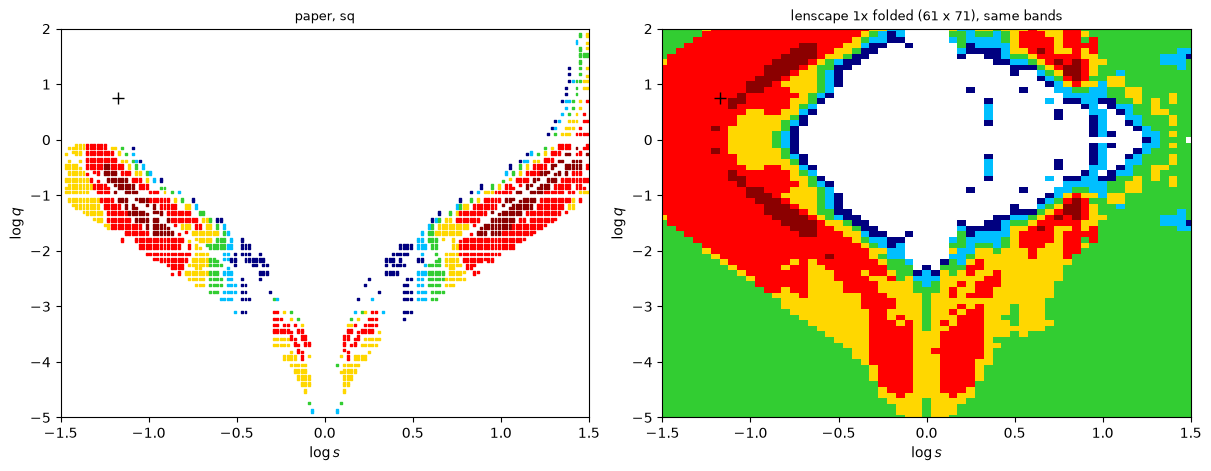

In [8]:
def lowest_ref():
    return min([chi2_best] + [float(np.nanmin(m["chi2"])) for _, m, _ in OURS])

ref = lowest_ref()
fig, axs = plt.subplots(len(OURS), 2, figsize=(12, 4.6 * len(OURS)), constrained_layout=True, squeeze=False)
for row, (name, m, panel) in enumerate(OURS):
    sr, qr = PANELS[panel]
    sel = paper["panel"] == panel
    axs[row, 0].scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap,
                        vmin=-0.5, vmax=len(EDGES) + 0.5, marker="s", s=2)
    axs[row, 0].set_title(f"paper, {panel}", fontsize=9)
    band = np.searchsorted(EDGES, m["chi2"] - ref)
    axs[row, 1].pcolormesh(m["logs"], m["logq"], band.T, cmap=band_cmap, vmin=-0.5, vmax=len(EDGES) + 0.5,
                           shading="nearest")
    axs[row, 1].set_title(f"lenscape {name} ({m['chi2'].shape[0]} x {m['chi2'].shape[1]}), same bands", fontsize=9)
    for ax in axs[row]:
        ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
        ax.plot(best[3], best[4], "k+", ms=9)

# our band at each coloured point of the paper (nearest lattice point inside our map)
for name, m, panel in OURS:
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, m["chi2"][i, j] - ref) + 1
    pb = paper["band"][sel]
    print(f"{name}: {sel.sum()} coloured paper points; our band the same at {100 * np.mean(ours == pb):.0f} %, within "
          f"one band at {100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

Folding improved 575 of the 3455 points with Δχ² < 49: 307 by more than 2, 197 by more than 5. Our map is now
symmetric about log *q* = 0, as it must be. The paper's map is not: it shows the close stellar-binary valley only
below log *q* = 0, although its Table lists the close binary BC at log *q* = +1.15, the mirror of a point inside
that valley.

The **level** differs, the **pattern** agrees. On the public data almost the whole plane lies within 25 of the
minimum (73 % of our points; every point with log *q* < −3, median 19.5), because a single lens is only 17 worse.
The paper's map rises above 49 everywhere outside its valleys; that contrast comes from the LCOGT data at the peak.
So the band agreement (a quarter of the paper's coloured points in the same band, 61 % within one band) mostly
measures the missing data, not the map.

The pattern is the paper's:
* the low-*q* valley narrows toward log *s* = 0, with two lobes on either side at log *q* ≈ −3.5 to −5 (red in both
  maps);
* the close stellar-binary valley runs diagonally from (−1.5, −0.5) to (−0.5, −2);
* the wide one runs from (+0.5, −2) to (+1.5, 0).

Our lowest band (< 4) lies in the close binary valley at log *s* ≈ −1.0 to −0.7, where the paper's map also has its
darkest points.

### Accuracy of the map values

The maps are computed with lenscape's fast grid backend (relative magnification accuracy about 3 × 10⁻³); the best
fit uses the accurate refine backend. Where many precise points sit at high magnification, the difference can reach a
few χ², which matters for band edges of 4 and 9. Here every map point is evaluated again with the refine backend at
its stored parameters (no refit: an upper bound on the accurate profile χ²), and the band comparison is repeated.
Stored in `data/`; this takes a minute or two.

In [9]:
be_exact = lenscape.make_backend(lenscape.config.REFINE_BACKEND)


def exact_chi2(name, m):
    path = f"data/kb251314_map_{name.replace(' ', '_')}_exact.npy"
    if not RECOMPUTE and os.path.exists(path):
        return np.load(path)
    ex = np.empty_like(m["chi2"])
    for i, ls in enumerate(m["logs"]):
        for j, lq in enumerate(m["logq"]):
            t0, u0, tE, al, lr = m["pars"][i, j]
            ex[i, j] = lenscape.model.chi2(be_exact, np.array([t0, u0, tE, ls, lq, al, lr]), data)
    np.save(path, ex)
    return ex


for name, m, panel in OURS:
    ex = exact_chi2(name, m)
    dd = (ex - m["chi2"])[m["chi2"] - ref < EDGES[-1]]
    print(f"{name}: accurate minus map chi2 where Delta chi2 < {EDGES[-1]:g}: median {np.median(dd):+.2f}, "
          f"5-95 % {np.percentile(dd, 5):+.2f} .. {np.percentile(dd, 95):+.2f}; accurate minimum {ex.min():.2f} "
          f"(map {np.nanmin(m['chi2']):.2f}, best fit {chi2_best:.2f})")
    rex = min(chi2_best, ex.min())
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, ex[i, j] - rex) + 1
    pb = paper["band"][sel]
    print(f"   with accurate values: band the same at {100 * np.mean(ours == pb):.0f} %, within one band at "
          f"{100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

1x folded: accurate minus map chi2 where Delta chi2 < 49: median +1.04, 5-95 % -0.01 .. +7.85; accurate minimum 1058.61 (map 1055.04, best fit 1060.00)
   with accurate values: band the same at 15 %, within one band at 55 %, above the last band at 1 %


For this event the map values are uncertain at the level of the first band edges. Evaluated with the accurate
backend, the points with Δχ² < 49 rise by 1.0 (median) and by up to 8 at 5 % of them. The cause is the
high-magnification peak (*u*₀ ≈ 0.005, ρ ≈ 0.007) sampled densely by the auto-follow-up, where the grid backend's
accuracy limit shows. Above Δχ² ≈ 200 a few dozen points differ by more; those are resonant large-ρ fits far from
any solution.

With the accurate values the band agreement drops (15 % same band, 55 % within one band): relative to the minimum,
our values are now slightly higher in the valleys. The accurate minimum, 1058.6 at (−0.75, −1.3) and its mirror, is 1.4 below our
best fit: the lattice found a slightly better close-binary solution than the fits started from the published ones.

### Local minima of our map

Lattice points lower than all eight neighbours, with their Δχ² and fitted parameters, next to the published
solutions:

In [10]:
def local_minima(m, max_dchi2):
    c = m["chi2"]; out = []
    for i in range(1, c.shape[0] - 1):
        for j in range(1, c.shape[1] - 1):
            nb = c[i - 1:i + 2, j - 1:j + 2]
            if m.get("folded") and m["logq"][j] > 1e-9:
                continue                                   # folded map: the mirror half repeats the minima
            if c[i, j] <= nb.min() and c[i, j] - ref < max_dchi2:
                out.append((c[i, j] - ref, m["logs"][i], m["logq"][j], m["pars"][i, j]))
    return sorted(out, key=lambda z: z[0])

for name, m, panel in OURS:
    print(f"{name}:")
    for dc, ls, lq, x in local_minima(m, EDGES[-1])[:15]:
        print(f"  Delta chi2 {dc:7.1f}  log s {ls:+.3f}  log q {lq:+.3f}  tE {abs(x[2]):6.1f} d  log rho {x[4]:+.2f}")

1x folded:
  Delta chi2     0.0  log s -0.700  log q -1.500  tE   58.3 d  log rho -2.54
  Delta chi2     1.7  log s +0.800  log q -1.300  tE   58.8 d  log rho -2.54
  Delta chi2     3.1  log s +0.650  log q -1.600  tE   59.4 d  log rho -2.56
  Delta chi2     3.6  log s -1.200  log q -0.200  tE   56.2 d  log rho -2.56
  Delta chi2     3.9  log s -0.550  log q -2.100  tE   53.4 d  log rho -2.12
  Delta chi2     4.1  log s -0.450  log q -2.400  tE   54.7 d  log rho -2.13
  Delta chi2     5.0  log s +0.350  log q -2.700  tE   56.3 d  log rho -2.14
  Delta chi2     5.5  log s -0.300  log q -2.900  tE   57.0 d  log rho -2.15
  Delta chi2     5.8  log s -0.350  log q -2.100  tE   42.4 d  log rho -2.04
  Delta chi2     6.1  log s -0.400  log q -2.700  tE   74.3 d  log rho -2.26
  Delta chi2     6.2  log s +0.550  log q -1.800  tE   57.0 d  log rho -2.17
  Delta chi2     6.2  log s +0.100  log q -3.700  tE   72.2 d  log rho -2.74
  Delta chi2     6.3  log s -0.100  log q -3.700  tE   71.6 d  lo

In [11]:
print("published solutions (Table of the paper):")
for name, sol in SOLUTIONS.items():
    print(f"  {name:22s} log s {np.log10(sol[3]):+.3f}  log q {np.log10(sol[4]):+.3f}  tE {sol[2]:6.1f} d")

published solutions (Table of the paper):
  close planet finite    log s -0.123  log q -3.650  tE   74.0 d
  close planet point     log s -0.255  log q -3.238  tE   71.4 d
  wide planet finite     log s +0.126  log q -3.621  tE   74.5 d
  wide planet point      log s +0.279  log q -3.177  tE   70.5 d
  close binary BC        log s -1.041  log q +1.148  tE   66.8 d
  wide binary DA         log s +1.134  log q -0.977  tE   70.6 d


**The lowest local minima are stellar binaries.** They sit at log *q* between −1.6 and −1.3, at log *s* ≈ −0.7 or
+0.65 to +0.8. Their *t*ₑ is about 58 d, shorter than the paper's 66 to 75 d, and their ρ is larger (log ρ ≈ −2.5).

**The planetary minima are recovered.** At Δχ² ≈ 6 the folded map has four minima at log *s* = ±0.10 and ±0.15,
log *q* = −3.5 to −3.7, with *t*ₑ = 67 to 72 d and log ρ = −2.74. These are the paper's close and wide finite-source
planets (log *s* = −0.123 and +0.126, log *q* ≈ −3.6, *t*ₑ ≈ 74 d, log ρ ≈ −2.74).

On the accurate values, the published solutions sit at:
* planetary solutions: 3 to 4 above the minimum (6 to 7 on the map values);
* close binary BC: 1.7;
* wide binary DA: 17.

So the public KMTNet data reproduce the planet/binary degeneracy but cannot rank its members. The paper's ranking
and its ρ measurement rest on the LCOGT data.

## Why we do not densify this map

For the other examples the next step was a 2× densify or a zoom. Here it would cost about half a day and change no
conclusion:

* **The structure is resolved.** Every feature (the two binary valleys, the planetary lobes, the gap between them)
  spans many lattice points. The folded map already has its minima at the published planetary and binary solutions,
  with the published *t*ₑ and ρ.
* **The 1× fits are mostly converged.** Folding was in effect a second, independent fit at every mirrored point. It
  improved 9 % of the relevant points by more than 2, so a densify would mostly repair a similar few per cent.
* **The data, not the lattice, limit the map.** Without the LCOGT data a single lens is only 17 worse than the best
  fit, and all published solutions lie within 4 of the minimum. Finer sampling cannot separate solutions that the
  data do not separate.
* **The map values are not accurate enough to rank the solutions.** The grid backend's error at this peak (median
  +1, up to +8) is as large as the differences between the solutions (planets 3 to 4, binaries 0 to 2). A densify
  with the same backend inherits that error. Ranking them needs refits with the accurate backend, not more points.
* **Cost.** A 2× restricted to log *q* ≤ 0 (the symmetry makes the rest redundant) is a 121 × 101 lattice with about
  9,000 new points, about 8 to 14 hours on 20 threads at the rate of the 1× map.

A densify becomes worthwhile only with data that separate the solutions, here the LCOGT light curves. Any map of
this event should cover log *q* ≤ 0 only.